In [3]:
# Telecom Churn Intelligence Platform

## 01 — Exploratory Data Analysis

# This notebook explores the telecom customer churn dataset,
# understands the structure and quality of the data, and identifies
# patterns that will guide preprocessing and machine learning.

In [5]:
import sys

print(sys.executable)
print(sys.version)

c:\Users\HP\Desktop\telecom-churn-intelligence\.venv\Scripts\python.exe
3.14.0 (tags/v3.14.0:ebf955d, Oct  7 2025, 10:15:03) [MSC v.1944 64 bit (AMD64)]


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
import pandas as pd

df = pd.read_excel("../data/raw/Telco_customer_churn.xlsx")

df.head()

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [8]:
df.shape

(7043, 33)

In [9]:
df.columns 

Index(['CustomerID', 'Count', 'Country', 'State', 'City', 'Zip Code',
       'Lat Long', 'Latitude', 'Longitude', 'Gender', 'Senior Citizen',
       'Partner', 'Dependents', 'Tenure Months', 'Phone Service',
       'Multiple Lines', 'Internet Service', 'Online Security',
       'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV',
       'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method',
       'Monthly Charges', 'Total Charges', 'Churn Label', 'Churn Value',
       'Churn Score', 'CLTV', 'Churn Reason'],
      dtype='str')

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   str    
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   str    
 3   State              7043 non-null   str    
 4   City               7043 non-null   str    
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   str    
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   str    
 10  Senior Citizen     7043 non-null   str    
 11  Partner            7043 non-null   str    
 12  Dependents         7043 non-null   str    
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   str    
 15  Multiple Lines     7043 non-null   str    
 16  Internet Service   7043 non-null   

In [11]:
df.isnull().sum()

CustomerID              0
Count                   0
Country                 0
State                   0
City                    0
Zip Code                0
Lat Long                0
Latitude                0
Longitude               0
Gender                  0
Senior Citizen          0
Partner                 0
Dependents              0
Tenure Months           0
Phone Service           0
Multiple Lines          0
Internet Service        0
Online Security         0
Online Backup           0
Device Protection       0
Tech Support            0
Streaming TV            0
Streaming Movies        0
Contract                0
Paperless Billing       0
Payment Method          0
Monthly Charges         0
Total Charges           0
Churn Label             0
Churn Value             0
Churn Score             0
CLTV                    0
Churn Reason         5174
dtype: int64

In [12]:
missing = df.isnull().sum()

missing_percentage = (missing/len(df))*100

missing_percentage[missing_percentage > 0]

Churn Reason    73.463013
dtype: float64

In [13]:
df["Churn Label"].value_counts(normalize=True) * 100

Churn Label
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

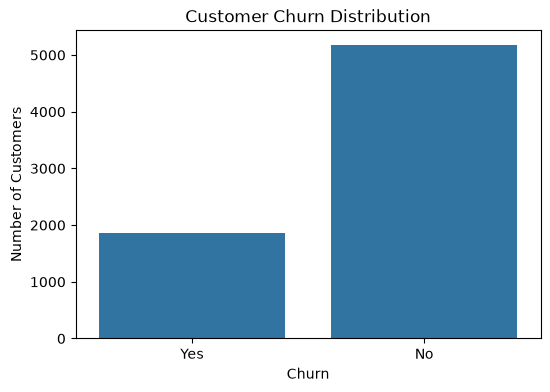

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize = (6,4))

sns.countplot(data=df, x="Churn Label")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

In [15]:
numerical_columns = df.select_dtypes(include=["int64","float64"]).columns
category_columns = df.select_dtypes(["object"]).columns

print("Numerical columns:")
print(numerical_columns.tolist())

print("Categorical columns:")
print(category_columns.tolist())

Numerical columns:
['Count', 'Zip Code', 'Latitude', 'Longitude', 'Tenure Months', 'Monthly Charges', 'Churn Value', 'Churn Score', 'CLTV']
Categorical columns:
['CustomerID', 'Country', 'State', 'City', 'Lat Long', 'Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method', 'Total Charges', 'Churn Label', 'Churn Reason']


C:\Users\HP\AppData\Local\Temp\ipykernel_20184\1507676235.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  category_columns = df.select_dtypes(["object"]).columns


In [16]:
df.describe()

,Count,Zip Code,Latitude,Longitude,Tenure Months,Monthly Charges,Churn Value,Churn Score,CLTV
count,7043.0,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,1.0,93521.964646,36.282441,-119.798880,32.371149,64.761692,0.265370,58.699418,4400.295755
std,0.0,1865.794555,2.455723,2.157889,24.559481,30.090047,0.441561,21.525131,1183.057152
min,1.0,90001.000000,32.555828,-124.301372,0.000000,18.250000,0.000000,5.000000,2003.000000
25%,1.0,92102.000000,34.030915,-121.815412,9.000000,35.500000,0.000000,40.000000,3469.000000
50%,1.0,93552.000000,36.391777,-119.730885,29.000000,70.350000,0.000000,61.000000,4527.000000
75%,1.0,95351.000000,38.224869,-118.043237,55.000000,89.850000,1.000000,75.000000,5380.500000
max,1.0,96161.000000,41.962127,-114.192901,72.000000,118.750000,1.000000,100.000000,6500.000000


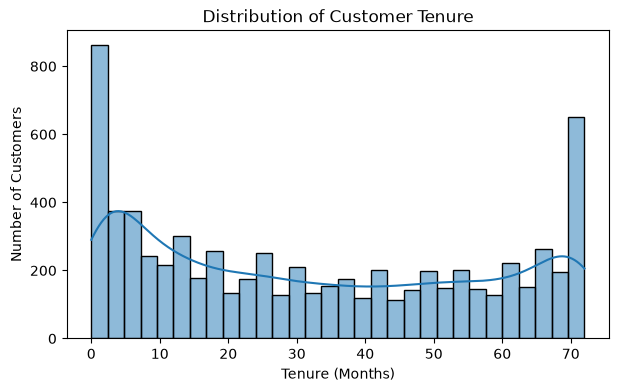

In [17]:
plt.figure(figsize=(7,4))

sns.histplot(data=df, x="Tenure Months",bins=30,kde=True)

plt.title("Distribution of Customer Tenure")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")

plt.show()


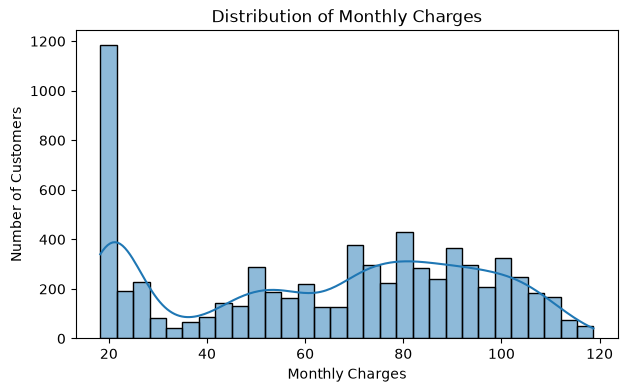

In [18]:
plt.figure(figsize=(7,4))

sns.histplot(data=df,x="Monthly Charges", bins = 30, kde = True)

plt.title("Distribution of Monthly Charges")
plt.xlabel("Monthly Charges")
plt.ylabel("Number of Customers")

plt.show()

In [19]:
df["Total Charges"].dtype

dtype('O')

In [20]:
df["Total Charges"].head(20)

0      108.15
1      151.65
2       820.5
3     3046.05
4      5036.3
5      528.35
6       39.65
7       20.15
8     4749.15
9        30.2
10     1093.1
11      316.9
12    3549.25
13     1105.4
14     144.15
15     1426.4
16      633.3
17    1752.55
18     857.25
19      79.35
Name: Total Charges, dtype: object

In [21]:
df[df["Total Charges"].str.strip() == ""]["Total Charges"].value_counts()

Total Charges
    11
Name: count, dtype: int64

In [22]:
df["Total Charges"].isna().sum()

np.int64(0)

In [23]:
df["Total Charges"] = pd.to_numeric(df["Total Charges"], errors="coerce")

In [24]:
df["Total Charges"].dtype

dtype('float64')

In [25]:
print(df["Total Charges"].isnull().sum())


11


In [26]:
missing_total = df[df["Total Charges"].isna()]

missing_total[["CustomerID", "Tenure Months", "Monthly Charges", "Total Charges"]]

,CustomerID,Tenure Months,Monthly Charges,Total Charges
2234,4472-LVYGI,0,52.55,NaN
2438,3115-CZMZD,0,20.25,NaN
2568,5709-LVOEQ,0,80.85,NaN
2667,4367-NUYAO,0,25.75,NaN
2856,1371-DWPAZ,0,56.05,NaN
4331,7644-OMVMY,0,19.85,NaN
4687,3213-VVOLG,0,25.35,NaN
5104,2520-SGTTA,0,20.00,NaN
5719,2923-ARZLG,0,19.70,NaN
6772,4075-WKNIU,0,73.35,NaN


In [27]:
missing_total["Tenure Months"].value_counts()

Tenure Months
0    11
Name: count, dtype: int64

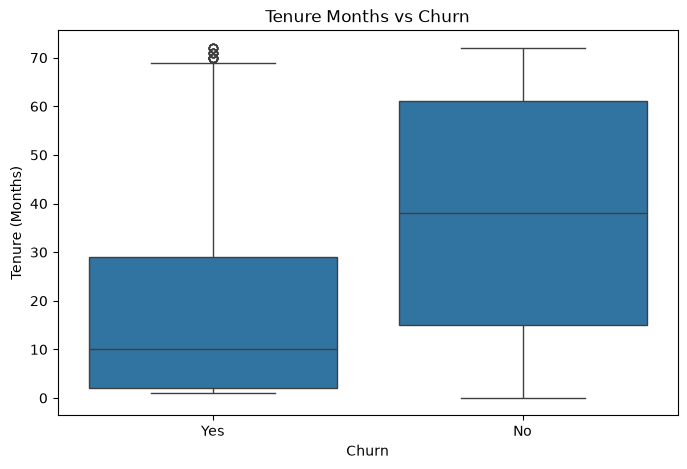

In [28]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn Label",
    y="Tenure Months"
)

plt.title("Tenure Months vs Churn")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")

plt.show()

In [29]:
df.groupby("Churn Label")["Tenure Months"].agg(
    ["count", "mean", "median", "min", "max"]
)

,count,mean,median,min,max
Churn Label,,,,,
No,5174,37.569965,38.0,0,72
Yes,1869,17.979133,10.0,1,72


In [30]:
df.groupby("Churn Label")["Monthly Charges"].agg(
    ["count", "mean", "median", "min", "max"]
)

,count,mean,median,min,max
Churn Label,,,,,
No,5174,61.265124,64.425,18.25,118.75
Yes,1869,74.441332,79.650,18.85,118.35


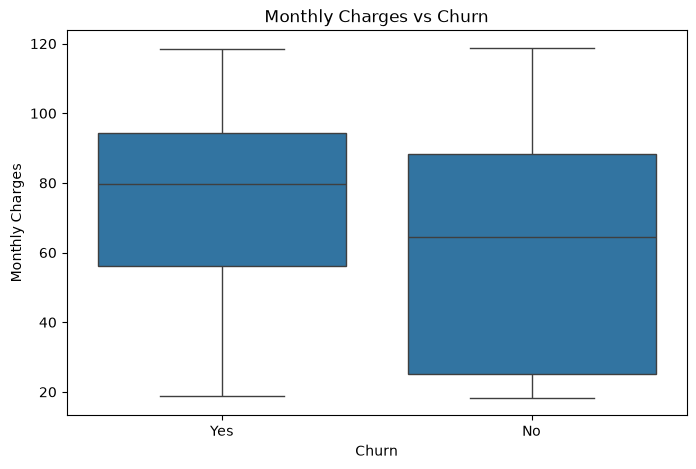

In [31]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data = df,
    x = "Churn Label",
    y = "Monthly Charges"
)

plt.xlabel("Churn")
plt.ylabel("Monthly Charges")
plt.title("Monthly Charges vs Churn")

plt.show()

In [32]:
df.groupby("Churn Label")["Monthly Charges"].agg(
    ["count", "mean", "median", "min", "max"]
)

,count,mean,median,min,max
Churn Label,,,,,
No,5174,61.265124,64.425,18.25,118.75
Yes,1869,74.441332,79.650,18.85,118.35


In [33]:
df.groupby("Contract")["Churn Label"].value_counts()

Contract        Churn Label
Month-to-month  No             2220
                Yes            1655
One year        No             1307
                Yes             166
Two year        No             1647
                Yes              48
Name: count, dtype: int64

In [34]:
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn Label"],
    normalize="index"
) * 100

contract_churn

Churn Label,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


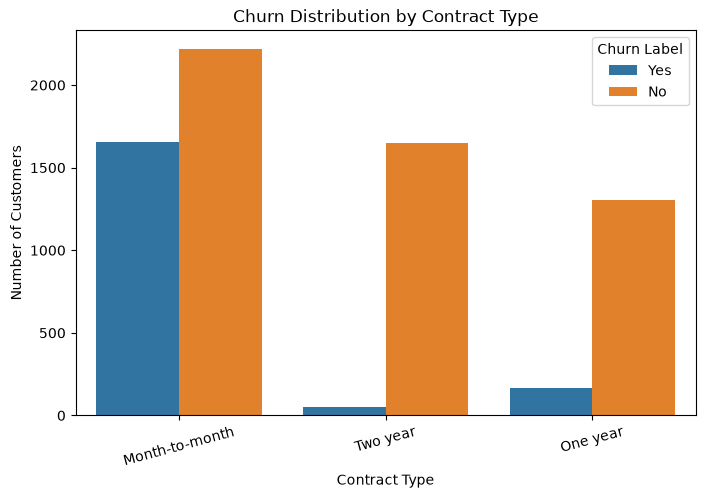

In [35]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Contract",
    hue="Churn Label"
)

plt.title("Churn Distribution by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)

plt.show()

In [37]:
internet_churn = pd.crosstab(
    df["Internet Service"],
    df["Churn Label"],
    normalize="index"
) * 100

internet_churn

Churn Label,No,Yes
Internet Service,,
DSL,81.040892,18.959108
Fiber optic,58.107235,41.892765
No,92.595020,7.404980


Internet Service type is strongly associated with churn in this dataset, with fiber-optic customers showing a substantially higher observed churn rate than DSL and customers without internet service.

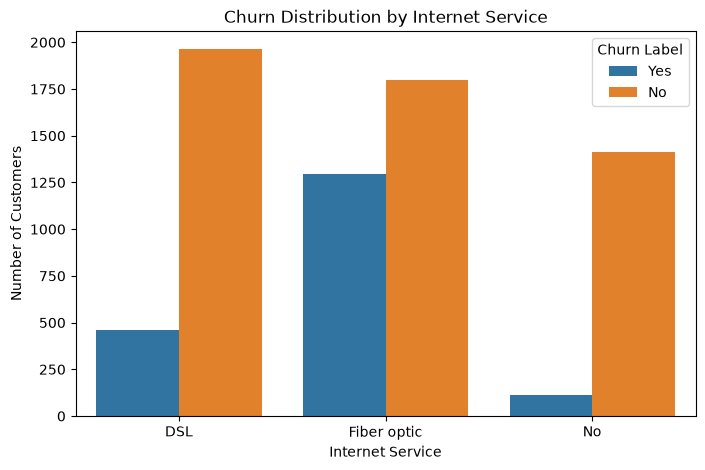

In [38]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Internet Service",
    hue="Churn Label"
)

plt.title("Churn Distribution by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Number of Customers")

plt.show()

In [39]:
payment_churn = pd.crosstab(
    df["Payment Method"],
    df["Churn Label"],
    normalize="index"
) * 100

payment_churn

Churn Label,No,Yes
Payment Method,,
Bank transfer (automatic),83.290155,16.709845
Credit card (automatic),84.756899,15.243101
Electronic check,54.714588,45.285412
Mailed check,80.893300,19.106700


Payment method is associated with churn, with electronic-check customers showing a substantially higher observed churn rate than customers using the other payment methods.

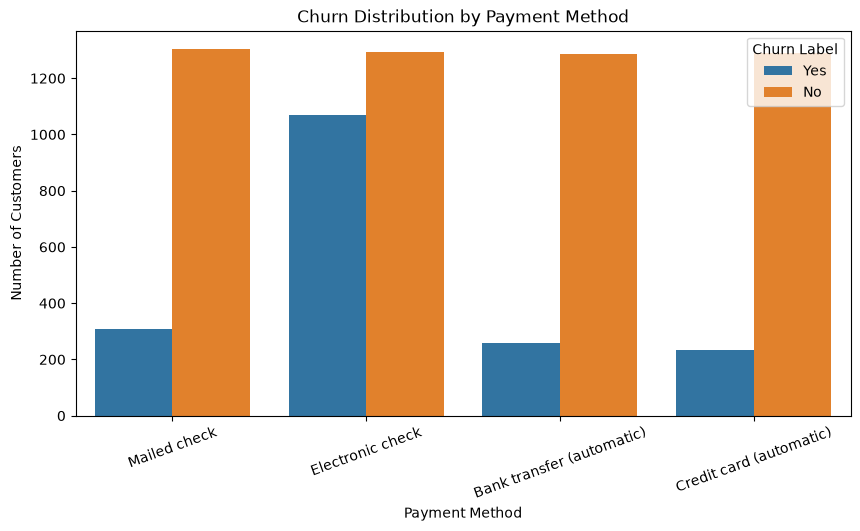

In [40]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="Payment Method",
    hue="Churn Label"
)

plt.title("Churn Distribution by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Customers")
plt.xticks(rotation=20)

plt.show()

In [42]:
tech_churn = pd.crosstab(
    df["Tech Support"],
    df["Churn Label"],
    normalize="index"
) * 100

tech_churn

Churn Label,No,Yes
Tech Support,,
No,58.364526,41.635474
No internet service,92.595020,7.404980
Yes,84.833659,15.166341


<function matplotlib.pyplot.show(close=None, block=None)>

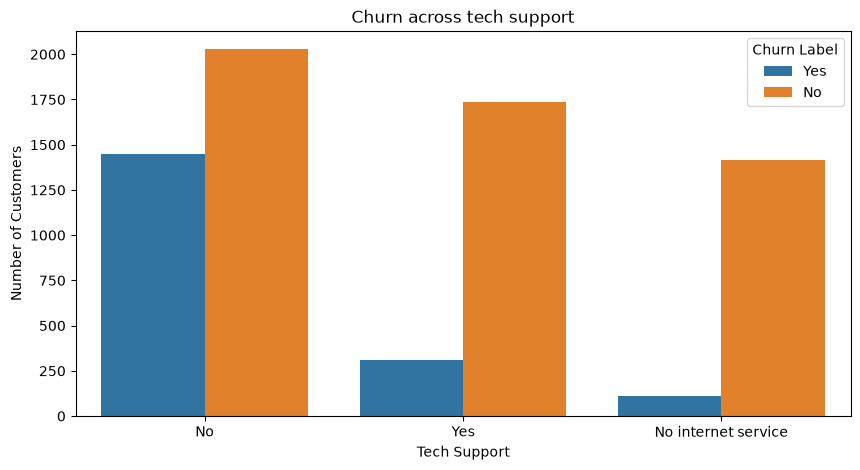

In [44]:
plt.figure(figsize=(10,5))

sns.countplot(
    data = df,
    x = "Tech Support",
    hue = "Churn Label"
)

plt.title("Churn across tech support")
plt.xlabel("Tech Support")
plt.ylabel("Number of Customers")

plt.show

Tech Support availability is strongly associated with churn in this dataset. Customers without tech support show a substantially higher observed churn rate than customers with tech support.

In [45]:
security_churn = pd.crosstab(
    df["Online Security"],
    df["Churn Label"],
    normalize="index"
)*100
security_churn

Churn Label,No,Yes
Online Security,,
No,58.233276,41.766724
No internet service,92.595020,7.404980
Yes,85.388806,14.611194


<function matplotlib.pyplot.show(close=None, block=None)>

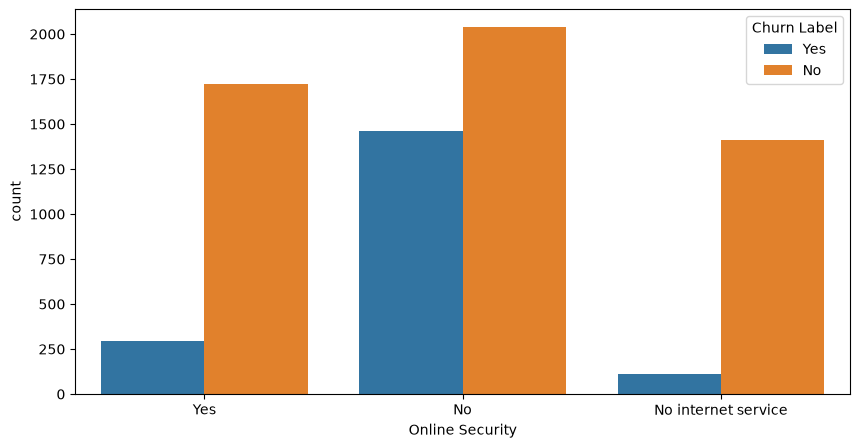

In [ ]:
plt.figure(figsize=(10,5))

sns.countplot(
    data = df,
    x = "Online Security",
    hue = "Churn Label"
)


plt.show

Online Security is strongly associated with churn in this dataset. Customers without online security show a substantially higher observed churn rate than customers with online security.

In [52]:
backup_churn = pd.crosstab(
    df["Online Backup"],
    df["Churn Label"],
    normalize="index"
)*100
backup_churn

Churn Label,No,Yes
Online Backup,,
No,60.071244,39.928756
No internet service,92.595020,7.404980
Yes,78.468506,21.531494


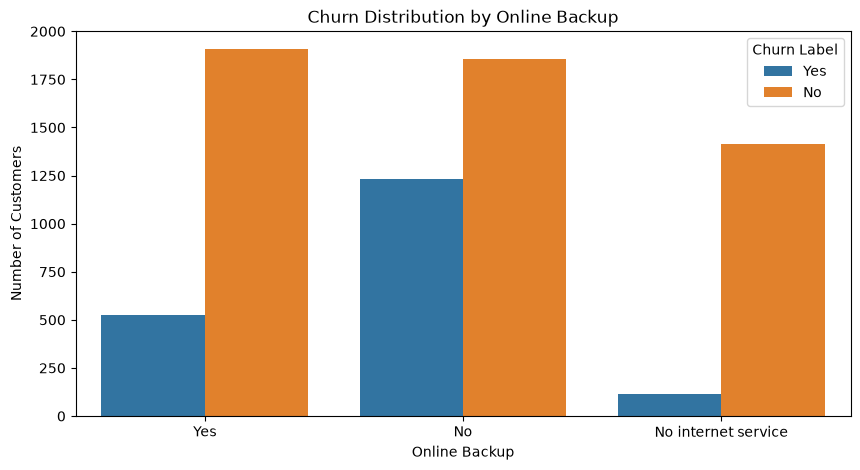

In [53]:
plt.figure(figsize=(10,5))

sns.countplot(
    data = df,
    x = "Online Backup",
    hue = "Churn Label"
)
plt.title("Churn Distribution by Online Backup")
plt.xlabel("Online Backup")
plt.ylabel("Number of Customers")

plt.show()

In [54]:
device_churn = pd.crosstab(
    df["Device Protection"],
    df["Churn Label"],
    normalize="index"
) * 100

device_churn

Churn Label,No,Yes
Device Protection,,
No,60.872375,39.127625
No internet service,92.595020,7.404980
Yes,77.497936,22.502064


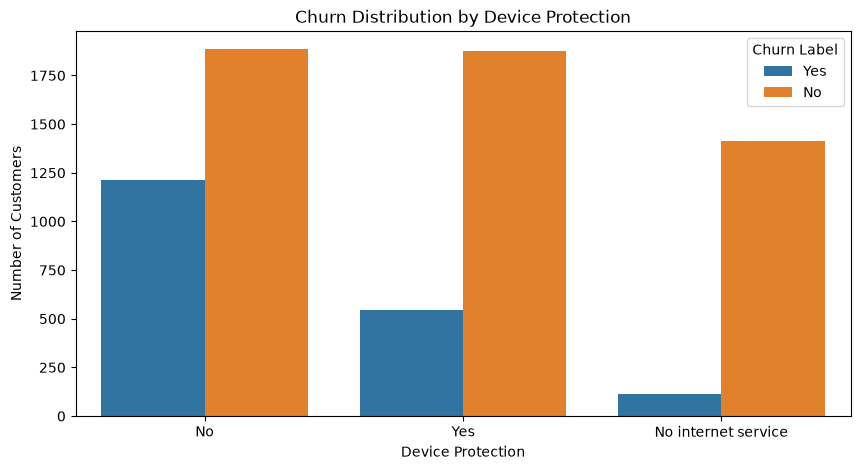

In [55]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="Device Protection",
    hue="Churn Label"
)

plt.title("Churn Distribution by Device Protection")
plt.xlabel("Device Protection")
plt.ylabel("Number of Customers")

plt.show()